In [5]:
from datasets import load_dataset, VerificationMode

dataset = load_dataset(
    "Parveshiiii/AI-vs-Real",
    verification_mode=VerificationMode.NO_CHECKS
)

print(dataset)

README.md:   0%|          | 0.00/3.06k [00:00<?, ?B/s]

data/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  205MB            

data/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  309MB            

data/train-00001-of-00005.parquet: downloading bytes:           |  0.00B            

...

data/train-00003-of-00005.parquet: downloading bytes:           |  0.00B            

data/train-00004-of-00005.parquet: reconstructing file:   0%|          |  0.00B / 17.2MB            

data/train-00004-of-00005.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9999 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'binary_label'],
        num_rows: 13999
    })
})


In [6]:
from collections import Counter

labels = dataset["train"]["binary_label"]
counts = Counter(labels)

print("AI-generated images (0):", counts[0])
print("Real images (1):", counts[1])
print("Total images:", len(labels))

AI-generated images (0): 3333
Real images (1): 10666
Total images: 13999


In [11]:
from datasets import ClassLabel

dataset["train"] = dataset["train"].cast_column(
    "binary_label",
    ClassLabel(num_classes=2, names=["AI-generated", "Real"])
)

# First split: 70% train, 30% temporary
split1 = dataset["train"].train_test_split(
    test_size=0.30,
    seed=42,
    stratify_by_column="binary_label"
)

# Split the remaining 30% equally into validation and test
split2 = split1["test"].train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="binary_label"
)

train_data = split1["train"]
val_data = split2["train"]
test_data = split2["test"]

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Casting the dataset:   0%|          | 0/13999 [00:00<?, ? examples/s]

Train: 9799
Validation: 2100
Test: 2100


In [3]:
import numpy as np
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 64

def make_tf_dataset(hf_data, training=False):
    def generator():
        for row in hf_data:
            img = row["image"].convert("RGB").resize(IMG_SIZE)
            img = np.asarray(img, dtype=np.float32)
            yield img, np.float32(row["binary_label"])

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(128, 128, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.float32)
        )
    )

    if training:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_tf_dataset(train_data, training=True)
val_ds = make_tf_dataset(val_data)
test_ds = make_tf_dataset(test_data)

print("TensorFlow datasets created successfully!")

NameError: name 'train_data' is not defined

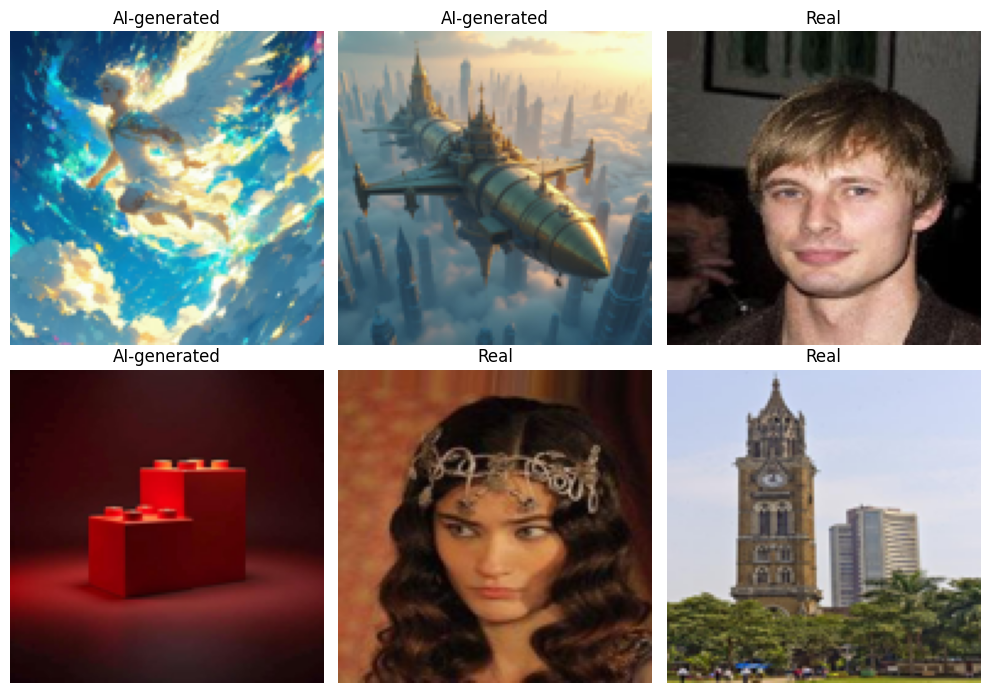

In [37]:
import matplotlib.pyplot as plt
import numpy as np

class_names = ["AI-generated", "Real"]

images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 7))

for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(np.clip(images[i].numpy(), 0, 255).astype("uint8"))

    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Rescaling, Conv2D, BatchNormalization,
    LeakyReLU, MaxPooling2D, Dropout,
    GlobalAveragePooling2D, Dense
)

model = Sequential([
    Input(shape=(128, 128, 3)),
    Rescaling(1./255),

    Conv2D(32, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,561 (431.88 KB)

 Trainable params: 110,113 (430.13 KB)

 Non-trainable params: 448 (1.75 KB)

In [23]:
from tensorflow.keras.callbacks import EarlyStopping
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )]

In [24]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = np.array(train_data["binary_label"])

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print(class_weights)

{0: 2.100085726532362, 1: 0.6562416287168498}


In [26]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/20
    154/Unknown 147s 816ms/step - accuracy: 0.7827 - loss: 0.4630

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


154/154 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8386 - loss: 0.3651 - val_accuracy: 0.7886 - val_loss: 0.5336
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 167s 994ms/step - accuracy: 0.8943 - loss: 0.2711 - val_accuracy: 0.8000 - val_loss: 0.6099
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 167s 994ms/step - accuracy: 0.9043 - loss: 0.2518 - val_accuracy: 0.8167 - val_loss: 0.5391
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 166s 990ms/step - accuracy: 0.9125 - loss: 0.2319 - val_accuracy: 0.8610 - val_loss: 0.3076
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 165s 985ms/step - accuracy: 0.9181 - loss: 0.2187 - val_accuracy: 0.7005 - val_loss: 0.6226
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 166s 989ms/step - accuracy: 0.9225 - loss: 0.2050 - val_accuracy: 0.9319 - val_loss: 0.1805
Epoch 7/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 166s 991ms/step - accuracy: 0.9137 - loss: 0.2278 - val_accuracy: 0.8524 - val_loss: 0.3567
Epoch 8/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.9248 - loss: 0.1990 - v

In [28]:
cnn_loss, cnn_acc = model.evaluate(test_ds)
print("Test Accuracy:", cnn_acc)
print("Test Loss:", cnn_loss)

33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 901ms/step - accuracy: 0.9557 - loss: 0.1233
Test Accuracy: 0.9557142853736877
Test Loss: 0.12330237776041031


In [39]:
from sklearn.metrics import f1_score
import numpy as np

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = (y_prob.ravel() >= 0.5).astype(int)

overall_f1 = f1_score(y_true, y_pred, average="macro")

print("Overall F1 Score:", round(overall_f1, 4))

33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 901ms/step
Overall F1 Score: 0.9382


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
